# 🚀 Huấn Luyện Tinh Chỉnh (Fine-Tuning) ResNet-18 v2 với Tỷ Lệ Trộn 2:1 & Early Stopping
**Tác giả:** Long  
**Kiến trúc:** ResNet-18 (Khởi đầu từ trọng số sạch `models/resnet18_long_v2_run_01.pth`)  
**Chiến lược Thích nghi Miền (Domain Adaptation - Cách 2):**
1. **Tập Thực địa Chính (68%):** Toàn bộ **10,959 phiến lá PlantDoc** (`data_plantdoc_leaves/train_split`).
2. **Tập Mỏ Neo Phòng Lab (32%):** Trích mẫu **5,130 ảnh `data_v2/train`** (~135 ảnh/lớp trên cả 38 lớp) để chống hiện tượng **Quên lãng thảm khốc (Catastrophic Forgetting)**.
3. **Khắc phục Triệt để Lỗi Lệch Nhãn (Zero Label Shift):** Ánh xạ 100% chuẩn xác theo từ điển 38 lớp của `models/class_indices.json`.
4. **Cơ chế Early Stopping:** `patience = 3`, theo dõi `val_macro_f1`. Tự động dừng khi mô hình đạt đỉnh bão hòa và lưu checkpoint tốt nhất.

In [1]:
import os
import sys
import time
import json
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import f1_score

sns.set_theme(style="whitegrid")
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Thiết lập thiết bị tính toán (GPU RTX 3050 Laptop)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Thiết bị sử dụng: {device}")
if device.type == "cuda":
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM Khả dụng: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")


🚀 Thiết bị sử dụng: cuda
   GPU Model: NVIDIA GeForce RTX 3050 6GB Laptop GPU
   VRAM Khả dụng: 5.67 GB


## 1. Xây Dựng Dataset Ánh Xạ Nhãn Chuẩn 38 Lớp & Trộn Dữ Liệu Tỷ Lệ 2:1

In [2]:
# 1. Đọc ánh xạ chuẩn 38 lớp (class_indices.json)
mapping_path = ROOT_DIR / "models" / "class_indices.json"
with open(mapping_path, encoding="utf-8") as f:
    class_mapping = json.load(f)
class_to_idx = class_mapping["class_to_idx"]
idx_to_class = {int(k): v for k, v in class_mapping["idx_to_class"].items()}
print(f"✅ Đã nạp từ điển chuẩn: {len(class_to_idx)} lớp bệnh")

# 2. Lớp Dataset tùy biến: Đảm bảo nhãn luôn khớp 100% với class_indices.json (Không bị lệch số)
class PlantDatasetWithMapping(Dataset):
    def __init__(self, root_dir, class_to_idx, max_per_class=None, transform=None, seed=42):
        self.samples = []
        self.transform = transform
        root = Path(root_dir)
        rng = random.Random(seed)
        
        for cls_dir in sorted(root.iterdir()):
            if not cls_dir.is_dir() or cls_dir.name not in class_to_idx:
                continue
            idx = class_to_idx[cls_dir.name]
            files = sorted([f for f in cls_dir.glob("*.*") if f.is_file()])
            if max_per_class and len(files) > max_per_class:
                rng.shuffle(files)
                files = files[:max_per_class]
            for f in files:
                self.samples.append((str(f), idx))
                
    def __len__(self):
        return len(self.samples)
        
    def __getitem__(self, i):
        path, label = self.samples[i]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

# 3. Định nghĩa Augmentations mô phỏng ánh sáng ngoài trời
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.05),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# 4. Nạp dữ liệu theo tỷ lệ 2:1
field_train_dir = ROOT_DIR / "data_plantdoc_leaves" / "train_split"
lab_train_dir   = ROOT_DIR / "data_v2" / "train"
val_dir         = ROOT_DIR / "data_plantdoc_leaves" / "val_split"
test_dir        = ROOT_DIR / "data_plantdoc_leaves" / "test"

ds_field = PlantDatasetWithMapping(field_train_dir, class_to_idx, transform=train_transforms)
ds_lab   = PlantDatasetWithMapping(lab_train_dir, class_to_idx, max_per_class=135, transform=train_transforms, seed=42)
train_ds = ConcatDataset([ds_field, ds_lab])

val_ds   = PlantDatasetWithMapping(val_dir, class_to_idx, transform=val_transforms)
test_ds  = PlantDatasetWithMapping(test_dir, class_to_idx, transform=val_transforms)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=4, pin_memory=True)

print(f"\n📊 PHÂN BỔ DỮ LIỆU HUẤN LUYỆN (TỶ LỆ 2:1):")
print(f"   - Lá Thực địa (PlantDoc) : {len(ds_field):5d} ảnh ({len(ds_field)/len(train_ds)*100:.1f}%)")
print(f"   - Ảnh Mỏ neo Lab (data_v2): {len(ds_lab):5d} ảnh ({len(ds_lab)/len(train_ds)*100:.1f}%)")
print(f"   -> TỔNG TẬP TRAIN        : {len(train_ds):5d} ảnh ({len(train_loader)} batches/epoch)")
print(f"   - Tập Validation         : {len(val_ds):5d} lá ({len(val_loader)} batches)")
print(f"   - Tập Test độc lập       : {len(test_ds):5d} lá ({len(test_loader)} batches)")


✅ Đã nạp từ điển chuẩn: 38 lớp bệnh



📊 PHÂN BỔ DỮ LIỆU HUẤN LUYỆN (TỶ LỆ 2:1):
   - Lá Thực địa (PlantDoc) : 10959 ảnh (68.1%)
   - Ảnh Mỏ neo Lab (data_v2):  5130 ảnh (31.9%)
   -> TỔNG TẬP TRAIN        : 16089 ảnh (252 batches/epoch)
   - Tập Validation         :  2310 lá (37 batches)
   - Tập Test độc lập       :   691 lá (11 batches)


## 2. Nạp Checkpoint Gốc ResNet-18 v2 & Cài đặt Bộ Tối Ưu

In [3]:
# Khởi tạo kiến trúc ResNet-18 chuẩn 38 lớp
model = torchvision.models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_to_idx))

# Nạp trọng số gốc từ phiên bản v2 (đạt 99.16% F1 trong phòng lab)
v2_checkpoint_path = ROOT_DIR / "models" / "resnet18_long_v2_run_01.pth"
assert v2_checkpoint_path.exists(), f"Thiếu checkpoint: {v2_checkpoint_path}"

ckpt = torch.load(v2_checkpoint_path, map_location="cpu")
state_dict = ckpt.get("model_state_dict", ckpt)
model.load_state_dict(state_dict)
model = model.to(device)
print(f"✅ Đã nạp thành công bộ não gốc từ: {v2_checkpoint_path.name}")

# Hàm mất mát Label Smoothing chống overfit trên nhãn nhiễu thực địa
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# Chiến lược Học phân tầng (Differential Learning Rates):
# - Lớp trích xuất đặc trưng (Backbone): lr nhỏ (8e-5) để bảo toàn bộ lọc cạnh/vân lá phòng lab
# - Đầu phân loại (Classifier Head): lr lớn hơn (3e-4) để tái căn chỉnh ranh giới phân lớp ngoài trời
param_groups = [
    {"params": [p for n, p in model.named_parameters() if "fc" not in n], "lr": 8e-5},
    {"params": model.fc.parameters(), "lr": 3e-4}
]
optimizer = optim.AdamW(param_groups, weight_decay=1e-4)

MAX_EPOCHS = 15
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS, eta_min=1e-6)


✅ Đã nạp thành công bộ não gốc từ: resnet18_long_v2_run_01.pth


## 3. Cài Đặt Cơ Chế Dừng Sớm (Early Stopping Class)

In [4]:
class EarlyStopping:
    def __init__(self, patience=4, min_delta=0.0, checkpoint_path=None):
        self.patience = patience
        self.min_delta = min_delta
        self.checkpoint_path = checkpoint_path
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_model_weights = None
        self.best_epoch = 0

    def __call__(self, val_metric, model, epoch):
        score = val_metric
        if self.best_score is None:
            self.best_score = score
            self.best_epoch = epoch
            self.save_checkpoint(score, model)
            print(f"   🌟 [EarlyStopping] Thiết lập kỷ lục ban đầu: {score:.2f}%. Lưu checkpoint!")
        elif score > self.best_score + self.min_delta:
            improvement = score - self.best_score
            print(f"   🌟 [EarlyStopping] KỶ LỤC MỚI: {self.best_score:.2f}% -> {score:.2f}% (+{improvement:.2f}%). Lưu checkpoint!")
            self.best_score = score
            self.best_epoch = epoch
            self.save_checkpoint(score, model)
            self.counter = 0
        else:
            self.counter += 1
            print(f"   ⚠️ [EarlyStopping] Không cải thiện ({self.counter}/{self.patience} epoch kiên nhẫn. Đỉnh cao nhất: {self.best_score:.2f}% ở Epoch {self.best_epoch}).")
            if self.counter >= self.patience:
                self.early_stop = True
                print(f"   🛑 [EarlyStopping] ĐẠT ĐỈNH BÃO HÒA! Dừng sớm tại Epoch {epoch}. Kỷ lục tốt nhất ở Epoch {self.best_epoch} ({self.best_score:.2f}%).")

    def save_checkpoint(self, score, model):
        self.best_model_weights = copy.deepcopy(model.state_dict())
        if self.checkpoint_path:
            torch.save({
                "epoch": self.best_epoch,
                "model_state_dict": model.state_dict(),
                "best_score": score
            }, self.checkpoint_path)

BEST_CKPT_PATH = ROOT_DIR / "models" / "resnet18_long_v2_finetuned_best.pth"
early_stopping = EarlyStopping(patience=4, min_delta=0.0, checkpoint_path=BEST_CKPT_PATH)


## 4. Vòng Lặp Huấn Luyện & Đánh Giá Tự Động

In [5]:
history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_macro_f1": []
}

scaler = torch.amp.GradScaler('cuda')

print(f"=======================================================")
print(f"🚀 BẮT ĐẦU FINE-TUNING RESNET-18 v2 (Tối đa {MAX_EPOCHS} Epochs)")
print(f"=======================================================")

start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    ep_start = time.time()
    
    # 1. Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{MAX_EPOCHS} [Train]", leave=False):
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        
        with torch.amp.autocast('cuda'):
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        running_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    scheduler.step()
    train_loss = running_loss / total
    train_acc = (correct / total) * 100.0
    
    # 2. Validation Phase
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    all_val_preds, all_val_labels = [], []
    
    with torch.no_grad():
        for imgs, labels in tqdm(val_loader, desc=f"Epoch {epoch:02d}/{MAX_EPOCHS} [Val]", leave=False):
            imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                outputs = model(imgs)
                loss = criterion(outputs, labels)
            
            val_running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
            
            all_val_preds.extend(preds.cpu().numpy())
            all_val_labels.extend(labels.cpu().numpy())
            
    val_loss = val_running_loss / val_total
    val_acc = (val_correct / val_total) * 100.0
    val_macro_f1 = f1_score(all_val_labels, all_val_preds, average="macro", zero_division=0) * 100.0
    ep_duration = time.time() - ep_start
    
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_macro_f1"].append(val_macro_f1)
    
    current_lr = scheduler.get_last_lr()[0]
    print(f"Epoch {epoch:02d} ({ep_duration:.1f}s) | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}% | Val F1: {val_macro_f1:.2f}%")
    
    # Kiểm tra Early Stopping
    early_stopping(val_macro_f1, model, epoch)
    if early_stopping.early_stop:
        break

total_duration = time.time() - start_time
print(f"\n=======================================================")
print(f"🏁 HUẤN LUYỆN HOÀN TẤT trong {total_duration/60.0:.1f} phút!")
print(f"🏆 Checkpoint Tốt Nhất: Epoch {early_stopping.best_epoch} với Val Macro F1: {early_stopping.best_score:.2f}%")
print(f"💾 Đã lưu tại: {BEST_CKPT_PATH.name}")
print(f"=======================================================")

# Phục hồi lại trọng số tốt nhất cho model
model.load_state_dict(early_stopping.best_model_weights)


🚀 BẮT ĐẦU FINE-TUNING RESNET-18 v2 (Tối đa 15 Epochs)

Epoch 01 (42.8s) | Train Loss: 1.6829 Acc: 66.85% | Val Loss: 2.1977 Acc: 48.74% | Val F1: 35.95%
🌟 [EarlyStopping] Thiết lập kỷ lục ban đầu: 35.95%. Lưu checkpoint!

Epoch 02 (1226.8s) | Train Loss: 1.4100 Acc: 75.55% | Val Loss: 2.1357 Acc: 51.73% | Val F1: 41.78%
🌟 [EarlyStopping] KỶ LỤC MỚI: 35.95% -> 41.78% (+5.82%). Lưu checkpoint!

Epoch 03 (41.7s) | Train Loss: 1.2959 Acc: 79.27% | Val Loss: 2.1108 Acc: 52.68% | Val F1: 42.35%
🌟 [EarlyStopping] KỶ LỤC MỚI: 41.78% -> 42.35% (+0.58%). Lưu checkpoint!

Epoch 04 (40.7s) | Train Loss: 1.2037 Acc: 82.93% | Val Loss: 2.1365 Acc: 55.41% | Val F1: 47.35%
🌟 [EarlyStopping] KỶ LỤC MỚI: 42.35% -> 47.35% (+5.00%). Lưu checkpoint!

Epoch 05 (40.8s) | Train Loss: 1.1436 Acc: 85.27% | Val Loss: 2.1376 Acc: 55.50% | Val F1: 45.29%
⚠️ [EarlyStopping] Không cải thiện (1/4 epoch kiên nhẫn. Đỉnh cao nhất: 47.35% ở Epoch 4).

Epoch 06 (43.2s) | Train Loss: 1.0795 Acc: 87.81% | Val Loss: 2.1390 A

## 5. Vẽ Biểu Đồ Tiến Trình Học & Kỷ Lục Early Stopping

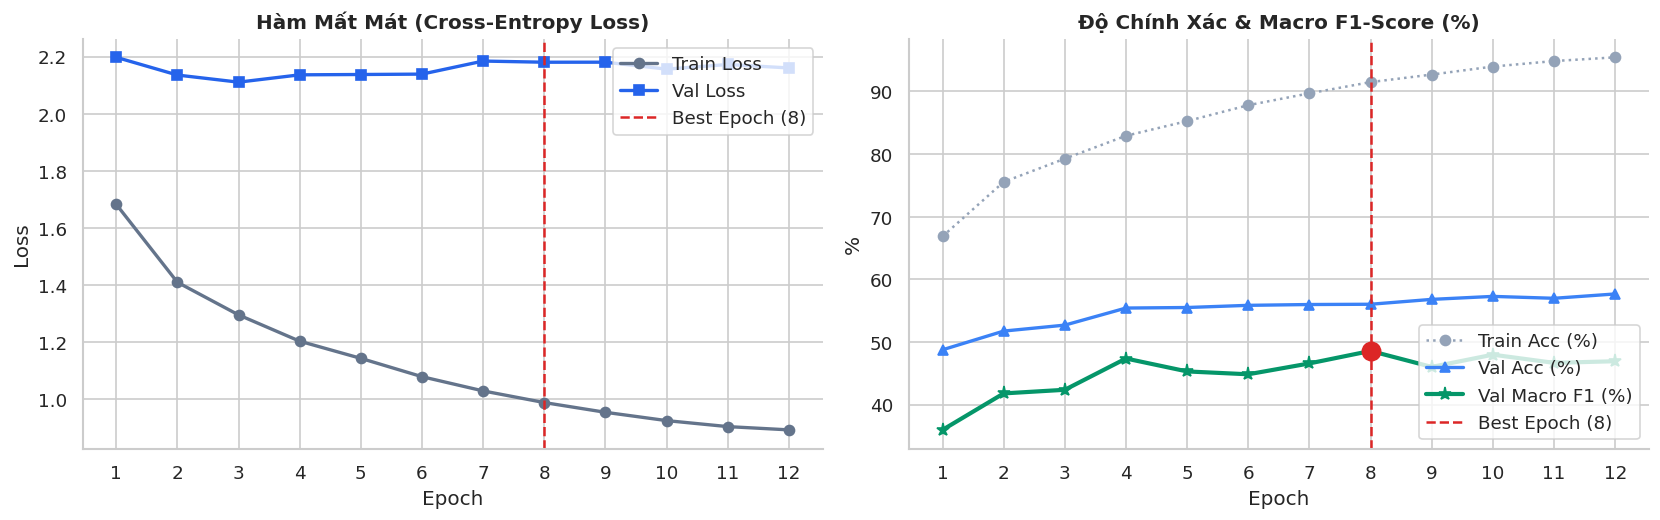

In [6]:
df_hist = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), dpi=120)

# Biểu đồ Loss
axes[0].plot(df_hist["epoch"], df_hist["train_loss"], marker="o", label="Train Loss", color="#64748b", linewidth=2.0)
axes[0].plot(df_hist["epoch"], df_hist["val_loss"], marker="s", label="Val Loss", color="#2563eb", linewidth=2.0)
axes[0].axvline(x=early_stopping.best_epoch, color="#dc2626", linestyle="--", label=f"Best Epoch ({early_stopping.best_epoch})")
axes[0].set_title("Hàm Mất Mát (Cross-Entropy Loss)", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(df_hist["epoch"])
axes[0].legend(loc="upper right", frameon=True, facecolor="white")
sns.despine(ax=axes[0])

# Biểu đồ Accuracy & F1
axes[1].plot(df_hist["epoch"], df_hist["train_acc"], marker="o", label="Train Acc (%)", color="#94a3b8", linestyle=":", linewidth=1.5)
axes[1].plot(df_hist["epoch"], df_hist["val_acc"], marker="^", label="Val Acc (%)", color="#3b82f6", linewidth=2.0)
axes[1].plot(df_hist["epoch"], df_hist["val_macro_f1"], marker="*", markersize=8, label="Val Macro F1 (%)", color="#059669", linewidth=2.5)
axes[1].axvline(x=early_stopping.best_epoch, color="#dc2626", linestyle="--", label=f"Best Epoch ({early_stopping.best_epoch})")
axes[1].scatter([early_stopping.best_epoch], [early_stopping.best_score], color="#dc2626", s=120, zorder=5)
axes[1].set_title("Độ Chính Xác & Macro F1-Score (%)", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("%")
axes[1].set_xticks(df_hist["epoch"])
axes[1].legend(loc="lower right", frameon=True, facecolor="white")
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()


## 6. Đánh Giá Khách Quan: Phiến Lá Đơn Lẻ & Toàn Bộ Cây Với Chiến Lược 2 (YOLO)

In [7]:
model.eval()

# 1. Đánh giá trên từng phiến lá đơn lẻ (691 lá test)
test_correct, test_total, top3_leaf_correct = 0, 0, 0
all_test_preds, all_test_labels = [], []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Chấm điểm phiến lá test"):
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.amp.autocast('cuda'):
            outputs = model(imgs)
        
        _, preds = torch.max(outputs, 1)
        test_correct += (preds == labels).sum().item()
        test_total += labels.size(0)
        
        _, top3 = torch.topk(outputs, 3, dim=1)
        for i in range(labels.size(0)):
            if labels[i] in top3[i]:
                top3_leaf_correct += 1
                
        all_test_preds.extend(preds.cpu().numpy())
        all_test_labels.extend(labels.cpu().numpy())

leaf_top1 = (test_correct / test_total) * 100.0
leaf_top3 = (top3_leaf_correct / test_total) * 100.0
leaf_f1   = f1_score(all_test_labels, all_test_preds, average="macro", zero_division=0) * 100.0

# 2. Đánh giá trên 236 ảnh thực tế ngoài vườn kết hợp Chiến lược 2 (YOLO bóc tách lá)
meta_path = ROOT_DIR / "notebooks" / "eda_reports" / "plantdoc_yolo_crops_meta.json"
with open(meta_path, "r", encoding="utf-8") as f:
    crops_meta = json.load(f)

raw_correct_top1, twostage_correct_top1, twostage_correct_top3 = 0, 0, 0
total_plantdoc_photos = len(crops_meta)

with torch.no_grad():
    for item in crops_meta:
        gt_cls = item["gt_class"]
        gt_idx = class_to_idx[gt_cls]
        
        # Đánh giá ảnh thô nguyên tấm
        raw_img = Image.open(ROOT_DIR / item["img_rel_path"]).convert("RGB")
        inp_raw = val_transforms(raw_img).unsqueeze(0).to(device)
        with torch.amp.autocast('cuda'):
            out_raw = model(inp_raw)
        top3_raw = torch.topk(out_raw, 3, dim=1).indices[0].cpu().tolist()
        if out_raw.argmax(dim=1).item() == gt_idx:
            raw_correct_top1 += 1
            
        # Đánh giá các lá cắt YOLO theo Chiến lược 2
        leaf_matches_top1 = []
        leaf_matches_top3 = []
        for lf in item["leaves"]:
            c_img = Image.open(ROOT_DIR / lf["crop_rel_path"]).convert("RGB")
            inp_c = val_transforms(c_img).unsqueeze(0).to(device)
            with torch.amp.autocast('cuda'):
                out_c = model(inp_c)
            p_c = out_c.argmax(dim=1).item()
            top3_c = torch.topk(out_c, 3, dim=1).indices[0].cpu().tolist()
            leaf_matches_top1.append(p_c == gt_idx)
            leaf_matches_top3.append(gt_idx in top3_c)
            
        if len(item["leaves"]) == 0:
            if out_raw.argmax(dim=1).item() == gt_idx:
                twostage_correct_top1 += 1
            if gt_idx in top3_raw:
                twostage_correct_top3 += 1
        else:
            if any(leaf_matches_top1):
                twostage_correct_top1 += 1
            if any(leaf_matches_top3):
                twostage_correct_top3 += 1

photo_raw_top1 = (raw_correct_top1 / total_plantdoc_photos) * 100.0
photo_ts_top1  = (twostage_correct_top1 / total_plantdoc_photos) * 100.0
photo_ts_top3  = (twostage_correct_top3 / total_plantdoc_photos) * 100.0

print(f"\n=======================================================")
print(f"🎯 KẾT QUẢ ĐÁNH GIÁ THỰC ĐỊA MÔ HÌNH 2 (TINH CHỈNH 2:1):")
print(f"=======================================================")
print(f"🍃 1. Điểm số trên 691 phiến lá cắt test:")
print(f"      - Top-1 Accuracy : {leaf_top1:.2f}%")
print(f"      - Top-3 Accuracy : {leaf_top3:.2f}%")
print(f"      - Macro F1-Score : {leaf_f1:.2f}%")
print(f"🌿 2. Điểm số trên 236 ảnh thực tế cả cây (PlantDoc Test):")
print(f"      - Ảnh thô nguyên tấm (Chưa qua YOLO) : {photo_raw_top1:.2f}%")
print(f"      - Hệ thống 2 Tầng (YOLO + Chiến lược 2): {photo_ts_top1:.2f}% (Top-3: {photo_ts_top3:.2f}%)")
print(f"=======================================================")


Chấm điểm phiến lá test:   0%|          | 0/11 [00:00<?, ?it/s]


🎯 KẾT QUẢ ĐÁNH GIÁ THỰC ĐỊA MÔ HÌNH 2 (TINH CHỈNH 2:1):
🍃 1. Điểm số trên 691 phiến lá cắt test:
      - Top-1 Accuracy : 53.84%
      - Top-3 Accuracy : 74.24%
      - Macro F1-Score : 51.93%
🌿 2. Điểm số trên 236 ảnh thực tế cả cây (PlantDoc Test):
      - Ảnh thô nguyên tấm (Chưa qua YOLO) : 54.24%
      - Hệ thống 2 Tầng (YOLO + Chiến lược 2): 75.00% (Top-3: 93.64%)


## 7. Xuất Mô Hình sang ONNX & Lượng Tử Hóa INT8 + Cập Nhật Sổ Đăng Ký

In [8]:
import onnx
from onnxruntime.quantization import quantize_dynamic, QuantType

ONNX_PATH = ROOT_DIR / "models" / "resnet18_long_v2_finetuned_best.onnx"
INT8_PATH = ROOT_DIR / "models" / "resnet18_long_v2_finetuned_best_int8.onnx"

model.eval().cpu()
dummy_input = torch.randn(1, 3, 224, 224, dtype=torch.float32)

print(f"📦 Đang xuất định dạng ONNX tiêu chuẩn...")
torch.onnx.export(
    model,
    dummy_input,
    str(ONNX_PATH),
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={"input": {0: "batch_size"}, "output": {0: "batch_size"}},
    opset_version=14,
    dynamo=False
)
print(f"✅ Đã xuất: {ONNX_PATH.name} ({ONNX_PATH.stat().st_size / (1024**2):.1f} MB)")

print(f"⚡ Đang lượng tử hóa INT8 Dynamic Quantization...")
quantize_dynamic(
    model_input=str(ONNX_PATH),
    model_output=str(INT8_PATH),
    weight_type=QuantType.QInt8
)
print(f"✅ Đã xuất bản INT8: {INT8_PATH.name} ({INT8_PATH.stat().st_size / (1024**2):.1f} MB)")

# Cập nhật sổ đăng ký Model Registry
registry_path = ROOT_DIR / "models" / "model_registry.csv"
now_str = time.strftime("%Y-%m-%d %H:%M:%S")
new_row = f"{now_str},resnet18,long,plantdoc_leaves_v2_mix,v2_finetuned,{photo_ts_top1:.2f}%,{leaf_f1:.2f}%,resnet18_long_v2_finetuned_best.pth,resnet18_long_v2_finetuned_best_int8.onnx\n"
with open(registry_path, "a", encoding="utf-8") as f:
    f.write(new_row)
print(f"📋 Đã cập nhật vào: {registry_path.name}")
print(f"🚀 Mô hình 2 đã sẵn sàng phục vụ cho Backend FastAPI và Web UI!")


📦 Đang xuất định dạng ONNX tiêu chuẩn...


/tmp/ipykernel_397866/913973091.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


✅ Đã xuất: resnet18_long_v2_finetuned_best.onnx (42.7 MB)
⚡ Đang lượng tử hóa INT8 Dynamic Quantization...


✅ Đã xuất bản INT8: resnet18_long_v2_finetuned_best_int8.onnx (10.7 MB)
📋 Đã cập nhật vào: model_registry.csv
🚀 Mô hình 2 đã sẵn sàng phục vụ cho Backend FastAPI và Web UI!
